# 阶段 4：增益模型评估（测试集）

所有评估都在测试集（40,008 人）上进行，评估函数是手写的 `src/uplift_eval.py`。

1. 手写指标和 scikit-uplift 在真实数据上再对一次
2. 增益曲线、Qini 曲线：最终模型 vs 响应模型 vs 随机
3. 按预测增益分 10 组，看实际增益是否依次下降
4. 不同发送比例下的增益（前 10% 到 100%）
5. 不确定性：bootstrap 置信区间、置换检验、最终模型与第二名的差异

## 4.1 手写指标与 scikit-uplift 对比（测试集，最终模型）

In [1]:
import json
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklift.metrics import qini_auc_score, uplift_at_k as sk_uplift_at_k, uplift_auc_score

from src.abtest import diff_in_means
from src.config import DATA_PROCESSED, RESULTS, SEED
from src.plotting import GRID, INK_SECONDARY, MARKERS, SERIES, setup_matplotlib
from src.uplift_eval import qini_auc, qini_curve, uplift_at_k, uplift_auc, uplift_by_bin, uplift_curve

setup_matplotlib()
test = pd.read_parquet(DATA_PROCESSED / "test_predictions.parquet")
summary3 = json.loads((RESULTS / "stage3_summary.json").read_text(encoding="utf-8"))
FINAL = summary3["最终模型（按验证集 Qini 系数）"]
RESPONSE = "响应模型（LightGBM，对照）"
comparison = pd.read_csv(RESULTS / "stage3_model_comparison.csv", header=[0, 1], index_col=0)
RUNNER_UP = comparison[("验证集", "Qini 系数")].drop(index=[FINAL, RESPONSE]).idxmax()
y, t = test["target"].to_numpy(), test["treatment_flg"].to_numpy()
u = test[FINAL].to_numpy()

metric_check = {
    "Qini 系数": {"手写": qini_auc(y, u, t), "scikit-uplift": float(qini_auc_score(y, u, t))},
    "AUUC": {"手写": uplift_auc(y, u, t), "scikit-uplift": float(uplift_auc_score(y, u, t))},
    "前30%增益（overall）": {"手写": uplift_at_k(y, u, t, 0.3, "overall"),
                         "scikit-uplift": float(sk_uplift_at_k(y, u, t, strategy="overall", k=0.3))},
    "前30%增益（by_group）": {"手写": uplift_at_k(y, u, t, 0.3, "by_group"),
                          "scikit-uplift": float(sk_uplift_at_k(y, u, t, strategy="by_group", k=0.3))},
}
print("最终模型：", FINAL, "| 验证集第二名：", RUNNER_UP)
pd.DataFrame(metric_check).T

最终模型： T-learner（逻辑回归） | 验证集第二名： X-learner（逻辑回归 + Ridge）


,手写,scikit-uplift
Qini 系数,0.012901,0.012901
AUUC,0.020013,0.020013
前30%增益（overall）,0.065712,0.065712
前30%增益（by_group）,0.065609,0.065609


## 4.2 增益曲线与 Qini 曲线

- 横轴：按预测增益从高到低，发给前多少比例的客户。
- 增益曲线的纵轴：如果发给这些人，预计多带来多少次购买（按测试集人数计）。
- 随机排序是一条从原点到终点的直线：随机发给 30% 的人，就只能拿到全部增量的 30%。
- 曲线越往左上方鼓，说明模型越能把“发了才会买”的人排在前面。

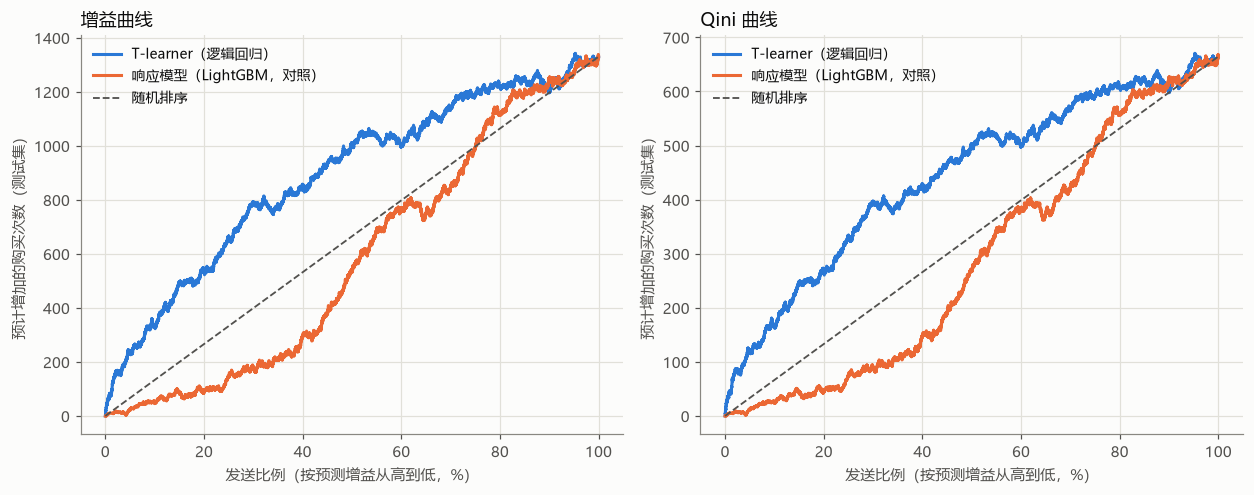

In [2]:
SHOW = {FINAL: SERIES[0], RESPONSE: SERIES[1]}
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
for ax, (curve_fn, title) in zip(axes, [(uplift_curve, "增益曲线"), (qini_curve, "Qini 曲线")]):
    for i, (name, color) in enumerate(SHOW.items()):
        x, v = curve_fn(y, test[name].to_numpy(), t)
        ax.plot(x / len(y) * 100, v, color=color, linewidth=2, label=name)
    ax.plot([0, 100], [0, v[-1]], color=INK_SECONDARY, linestyle="--", linewidth=1.2, label="随机排序")
    ax.set_xlabel("发送比例（按预测增益从高到低，%）")
    ax.set_ylabel("预计增加的购买次数（测试集）")
    ax.set_title(title, loc="left")
    ax.legend(frameon=False, fontsize=9, loc="upper left")
fig.tight_layout()
fig.savefig(RESULTS / "stage4_curves.png")
plt.show()

## 4.3 按预测增益分 10 组：实际增益是否依次下降？

第 1 组是预测增益最高的 10%。每组里分别计算“实验组购买率 − 对照组购买率”，这是这组人真实的平均增益（随机实验保证了它是因果效应）。好的模型应该让第 1 组最高，然后依次下降。

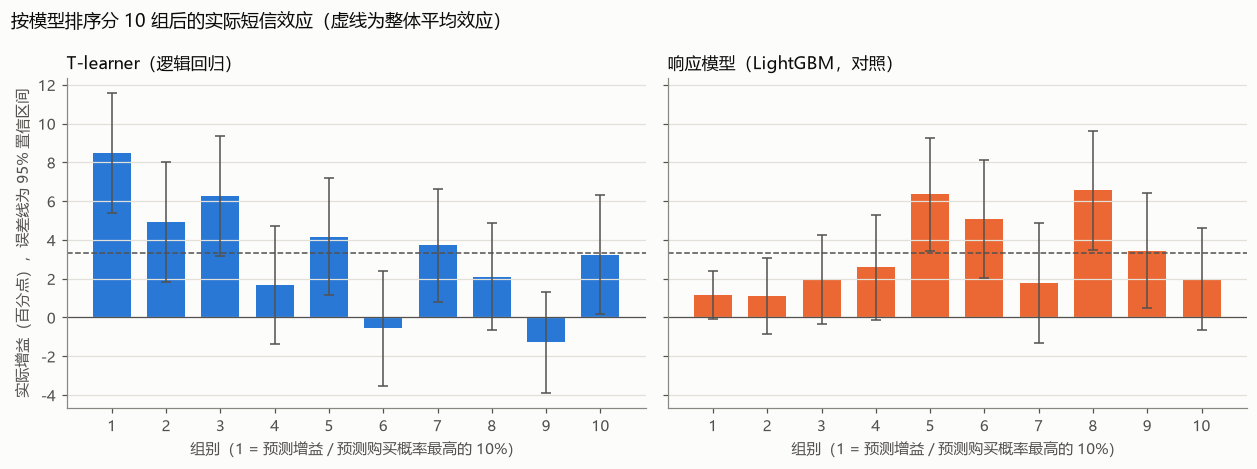

,组别,人数,预测增益均值,实验组购买率,对照组购买率,实际增益,实际增益标准误
0,1,4001,0.1096,0.5582,0.4735,0.0847,0.0157
1,2,4001,0.0666,0.5659,0.5166,0.0493,0.0157
2,3,4001,0.0504,0.5846,0.5220,0.0626,0.0157
3,4,4001,0.0388,0.6007,0.5840,0.0167,0.0155
4,5,4001,0.0297,0.6296,0.5879,0.0417,0.0154
5,6,4001,0.0215,0.6366,0.6422,-0.0056,0.0152
6,7,4001,0.0141,0.6918,0.6546,0.0373,0.0148
7,8,4001,0.0072,0.7431,0.7221,0.0211,0.0140
8,9,4000,0.0007,0.7630,0.7758,-0.0129,0.0133
9,10,4000,-0.0166,0.5902,0.5578,0.0324,0.0156


In [3]:
dec = {name: pd.DataFrame(uplift_by_bin(y, test[name].to_numpy(), t, 10)) for name in [FINAL, RESPONSE]}
dec_table = pd.concat(dec, names=["模型"]).reset_index(level=0)
dec_table.to_csv(RESULTS / "stage4_deciles.csv", index=False, encoding="utf-8-sig")
overall_ate = diff_in_means(y, t)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), sharey=True)
for ax, (name, color) in zip(axes, SHOW.items()):
    d = dec[name]
    ax.bar(d["组别"], d["实际增益"] * 100, color=color, width=0.7)
    ax.errorbar(d["组别"], d["实际增益"] * 100, yerr=1.96 * d["实际增益标准误"] * 100, fmt="none",
                ecolor=INK_SECONDARY, capsize=3, linewidth=1)
    ax.axhline(overall_ate["ATE"] * 100, color=INK_SECONDARY, linestyle="--", linewidth=1)
    ax.axhline(0, color=INK_SECONDARY, linewidth=0.8)
    ax.set_xticks(range(1, 11))
    ax.set_xlabel("组别（1 = 预测增益 / 预测购买概率最高的 10%）")
    ax.set_title(name, loc="left", fontsize=11)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("实际增益（百分点），误差线为 95% 置信区间")
fig.suptitle("按模型排序分 10 组后的实际短信效应（虚线为整体平均效应）", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(RESULTS / "stage4_deciles.png")
plt.show()
dec[FINAL].round(4)

## 4.4 不同发送比例下的增益

发给前 k% 的客户时，这群人里“实验组 − 对照组”的购买率差（前 k% 增益），以及这群人能带来的增量购买占全部增量的比例。

In [4]:
rows = []
x_f, v_f = uplift_curve(y, u, t)
x_r, v_r = uplift_curve(y, test[RESPONSE].to_numpy(), t)
total_gain = v_f[-1]
for k in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    n_k = int(len(y) * k)
    rows.append({"发送比例": k,
                 "前k%增益·最终模型": uplift_at_k(y, u, t, k) if k < 1 else overall_ate["ATE"],
                 "前k%增益·响应模型": uplift_at_k(y, test[RESPONSE].to_numpy(), t, k) if k < 1 else overall_ate["ATE"],
                 "增量占比·最终模型": float(np.interp(n_k, x_f, v_f) / total_gain),
                 "增量占比·响应模型": float(np.interp(n_k, x_r, v_r) / total_gain),
                 "增量占比·随机": k})
at_k = pd.DataFrame(rows)
at_k.to_csv(RESULTS / "stage4_uplift_at_k.csv", index=False, encoding="utf-8-sig")
at_k.round(4)

,发送比例,前k%增益·最终模型,前k%增益·响应模型,增量占比·最终模型,增量占比·响应模型,增量占比·随机
0,0.1,0.0845,0.0115,0.2541,0.0345,0.1
1,0.2,0.0670,0.0112,0.4034,0.0672,0.2
2,0.3,0.0657,0.0147,0.5931,0.1330,0.3
3,0.4,0.0534,0.0183,0.6430,0.2203,0.4
4,0.5,0.0504,0.0270,0.7583,0.4056,0.5
5,0.6,0.0416,0.0317,0.7512,0.5730,0.6
6,0.7,0.0405,0.0303,0.8538,0.6372,0.7
7,0.8,0.0382,0.0349,0.9186,0.8398,0.8
8,0.9,0.0334,0.0346,0.9033,0.9374,0.9
9,1.0,0.0332,0.0332,1.0000,1.0000,1.0


## 4.5 不确定性

- **bootstrap 置信区间**：从测试集里有放回地抽 40,008 人，重新计算指标，重复 500 次，取 2.5% 和 97.5% 分位数。
- **置换检验**：把预测值随机打乱（相当于一个完全没用的模型），算 500 次 Qini 系数，看最终模型的 Qini 系数超过了其中多少次。
- **最终模型 vs 第二名**：在同一批 bootstrap 样本上计算两者 Qini 系数的差，看差值的置信区间是否包含 0。

In [5]:
rng = np.random.default_rng(SEED)
B = 500
u_run = test[RUNNER_UP].to_numpy()
u_resp = test[RESPONSE].to_numpy()
boot = {"最终模型 Qini": [], "第二名 Qini": [], "Qini 差（最终 − 第二名）": [], "响应模型 Qini": [],
        "最终模型 前30%增益": [], "响应模型 前30%增益": []}
for _ in range(B):
    i = rng.integers(0, len(y), len(y))
    qf, qr = qini_auc(y[i], u[i], t[i]), qini_auc(y[i], u_run[i], t[i])
    boot["最终模型 Qini"].append(qf)
    boot["第二名 Qini"].append(qr)
    boot["Qini 差（最终 − 第二名）"].append(qf - qr)
    boot["响应模型 Qini"].append(qini_auc(y[i], u_resp[i], t[i]))
    boot["最终模型 前30%增益"].append(uplift_at_k(y[i], u[i], t[i], 0.3))
    boot["响应模型 前30%增益"].append(uplift_at_k(y[i], u_resp[i], t[i], 0.3))
point = {"最终模型 Qini": qini_auc(y, u, t), "第二名 Qini": qini_auc(y, u_run, t),
         "Qini 差（最终 − 第二名）": qini_auc(y, u, t) - qini_auc(y, u_run, t), "响应模型 Qini": qini_auc(y, u_resp, t),
         "最终模型 前30%增益": uplift_at_k(y, u, t, 0.3), "响应模型 前30%增益": uplift_at_k(y, u_resp, t, 0.3)}
ci = {k: {"点估计": point[k], "95%区间下限": float(np.percentile(v, 2.5)), "95%区间上限": float(np.percentile(v, 97.5))}
      for k, v in boot.items()}
perm = np.array([qini_auc(y, rng.permutation(u), t) for _ in range(B)])
perm_test = {"置换后 Qini 的均值": float(perm.mean()), "置换后 Qini 的 97.5% 分位数": float(np.percentile(perm, 97.5)),
             "置换后 Qini ≥ 最终模型的比例（p 值）": float((perm >= point["最终模型 Qini"]).mean())}
display(pd.DataFrame(ci).T.round(4))
perm_test

,点估计,95%区间下限,95%区间上限
最终模型 Qini,0.0129,0.0068,0.0195
第二名 Qini,0.0121,0.0058,0.0186
Qini 差（最终 − 第二名）,0.0008,-0.0011,0.0026
响应模型 Qini,-0.0052,-0.0113,0.0003
最终模型 前30%增益,0.0657,0.0485,0.0837
响应模型 前30%增益,0.0147,0.0026,0.0262


{'置换后 Qini 的均值': 0.0001867026399209686,
 '置换后 Qini 的 97.5% 分位数': 0.006821613274794176,
 '置换后 Qini ≥ 最终模型的比例（p 值）': 0.0}

## 4.6 保存结果

In [6]:
(RESULTS / "stage4_summary.json").write_text(json.dumps({
    "最终模型": FINAL, "验证集第二名": RUNNER_UP, "手写与 scikit-uplift 对比": metric_check,
    "bootstrap（B=500）": ci, "置换检验（B=500）": perm_test,
    "整体平均效应": overall_ate,
}, ensure_ascii=False, indent=2), encoding="utf-8")
print("已保存：stage4_curves.png、stage4_deciles.csv/png、stage4_uplift_at_k.csv、stage4_summary.json")

已保存：stage4_curves.png、stage4_deciles.csv/png、stage4_uplift_at_k.csv、stage4_summary.json
